# Session 10 — Speech Recognition

**Question:** how does a computer turn your voice into text?

**The idea in one line:** sound → a list of numbers → a **spectrogram** (an "image") → a **Transformer** (Whisper) → text.

**How it works:** just run the cells in order; there is nothing to complete. You need `soundfile` and `transformers`, and the file `sample_command.wav` next to this notebook. The first time, Whisper is downloaded (about 290 MB).

### 1. A sound is a list of numbers · *slide 14*

In [1]:
# PURPOSE: load the voice command and listen to it.
# HOW: soundfile reads the samples; a microphone measures the air pressure 16,000 times per second.

import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import torch
from IPython.display import Audio

audio, sr = sf.read("sample_command.wav", dtype="float32")
print(f"{len(audio):,} numbers at {sr:,} per second = {len(audio) / sr:.2f} seconds")
print("8 numbers from the middle:", np.round(audio[30000:30008], 4))
Audio(audio, rate=sr)

71,040 numbers at 16,000 per second = 4.44 seconds
8 numbers from the middle: [-0.0285 -0.0409 -0.0476 -0.0466 -0.0463 -0.0455 -0.0394 -0.0361]


### 2. From a list of numbers to an image: the spectrogram · *slide 15*

Cut the sound into short windows (25 ms, one every 10 ms), measure which frequencies are in each window, and put the windows side by side: **frequency × time = an image**.

spectrogram shape (frequencies, time steps): (201, 445)


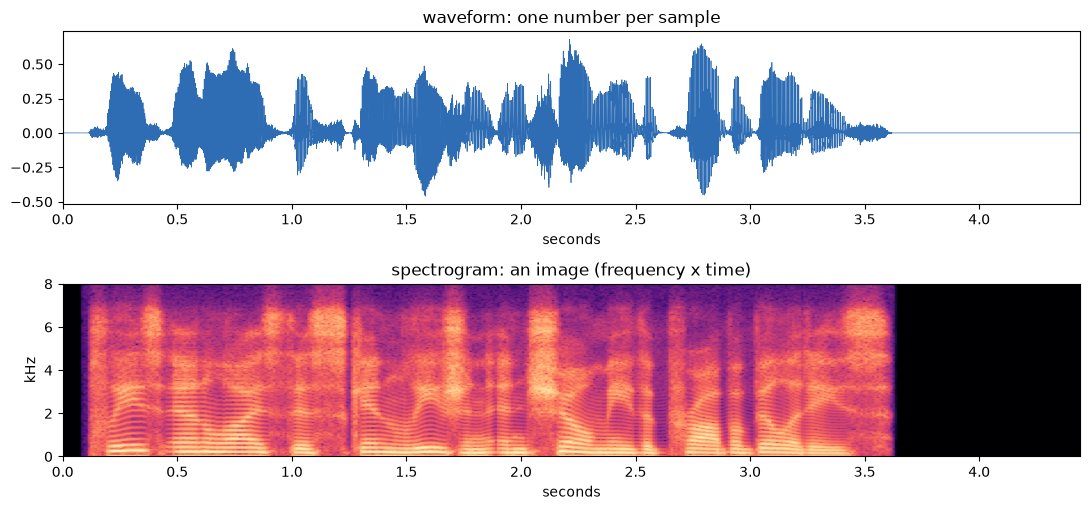

In [2]:
# PURPOSE: see the same sound as a waveform (1-D) and as a spectrogram (2-D).
# HOW: torch.stft measures the frequencies in windows of 400 samples, one every 160 samples.

spec = torch.stft(torch.from_numpy(audio), n_fft=400, hop_length=160,
                  window=torch.hann_window(400), return_complex=True).abs()
print("spectrogram shape (frequencies, time steps):", tuple(spec.shape))     # (201, 445)

t = np.arange(len(audio)) / sr
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2))
axes[0].plot(t, audio, color="#2E6DB4", lw=0.5)
axes[0].set_xlim(0, t[-1]); axes[0].set_title("waveform: one number per sample"); axes[0].set_xlabel("seconds")
axes[1].imshow((spec + 1e-6).log10(), origin="lower", aspect="auto", cmap="magma", extent=[0, t[-1], 0, sr / 2000])
axes[1].set_title("spectrogram: an image (frequency x time)"); axes[1].set_xlabel("seconds"); axes[1].set_ylabel("kHz")
plt.tight_layout()

### 3. Whisper: a Transformer that listens · *slide 16*

Whisper turns the sound into its own spectrogram, the **encoder** reads it (like the ViT of Session 9) and the **decoder** writes the text, word by word.

In [3]:
# PURPOSE: transcribe the voice command with a pretrained Whisper model.
# HOW: the transformers pipeline does spectrogram -> encoder -> decoder -> text in one call.

import warnings
from transformers import pipeline, logging as hf_logging
hf_logging.set_verbosity_error(); warnings.filterwarnings("ignore")

asr = pipeline("automatic-speech-recognition", model="openai/whisper-base", device="cpu")
result = asr({"raw": audio, "sampling_rate": sr}, generate_kwargs={"language": "en", "task": "transcribe"})
print("Whisper heard:", result["text"].strip())

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

Whisper heard: Please analyze this skin lesion and show me the probabilities.


### 4. Try it with your own voice (optional)

Record a short sentence with your phone or laptop (any language), save it as a **.wav** file next to this notebook, and write its name below. Whisper detects the language by itself; with `"task": "translate"` it translates into English.

In [4]:
# PURPOSE: transcribe your own recording.
# HOW: make it mono and 16,000 samples per second (what Whisper expects), then call the same pipeline.

from pathlib import Path
from scipy.signal import resample_poly

MY_FILE = Path("my_voice.wav")          # <- the name of your recording

if MY_FILE.exists():
    mine, my_sr = sf.read(MY_FILE, dtype="float32")
    if mine.ndim == 2:
        mine = mine.mean(axis=1)                       # stereo -> mono
    if my_sr != 16000:
        mine = resample_poly(mine, 16000, my_sr).astype("float32")   # e.g. 44,100 or 48,000 -> 16,000
    out = asr({"raw": mine, "sampling_rate": 16000}, generate_kwargs={"task": "transcribe"})
    print("Whisper heard:", out["text"].strip())
else:
    print(f"No file called {MY_FILE} yet: record one and run this cell again.")

No file called my_voice.wav yet: record one and run this cell again.


### What to remember

- A sound is a **list of numbers** (here 16,000 per second).
- A **spectrogram** turns it into an **image**: frequency × time.
- **Whisper** = a Transformer encoder (like ViT) + a decoder that writes the text; pretrained on 680,000 hours of audio.
- Same recipe as the whole course: turn the data into numbers, use a pretrained network, check the output.